# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [3]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head() # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head() # mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info() # inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info() # inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info() # inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Cantidad de nulos para users: ", users.isna().sum())
print("Proporción de nulos para users: ", users.isna().mean())

Cantidad de nulos para users:  user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de nulos para users:  user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Cantidad de nulos para usage: ", usage.isna().sum())
print('---')
print("Proporción de nulos para usage: ", usage.isna().mean())

Cantidad de nulos para usage:  id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
---
Proporción de nulos para usage:  id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

En el dataset **users**, las columnas con valores nulos son:
- **city**: 469 nulos, proporción 11.7% - se recomienda dejar como nulo.
- **churn_date**: 3534 nulos, proporción 88.3% - se recomienda ignorar, es la fecha de cancelación. Puede servir como dato para saber que el 88.3% de los usuarios mantiene un plan activo.

En el dataset **usage**, las columnas con valores nulos son:
- **date**: 50 nulos, proporción 0.125% - se recomienda ignorar o eliminar, no es relevante para el análisis.
- **duration**: 22076 nulos, proporción 55.2% - se recomienda investigar para imputar.
- **length**: 17896 nulos, proporción 44.7% - se recomienda investigar para imputar.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:

def columnas_numericas(users):
    columnas_user = ['user_id', 'age']
    for col in columnas_user:
        print(col)
        descripcion = users[col].describe()
        print(descripcion)
        mediana = users[col].median()
        print("La mediana es: ", mediana)
        print('---')
columnas_numericas(users)
 # explorar columnas numéricas de users

user_id
count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64
La mediana es:  11999.5
---
age
count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64
La mediana es:  47.0
---


- La columna `user_id` muestra 4000 registros de clientes que van desde el ID 10000 hasta el 13999. La media coincide con el percentil 50%, y la desviación estándar es alta. No hay indicadores que posibles outliers, parece una columna limpia.
- La columna `age` muestra 4000 registros de edad, tiene outliers en la edad mínima -999, lo cual altera la media. Al calcular la mediana (47) se observa una diferencia clara frente a la media (33). Esta columna necesita imputarse.

In [13]:
def columnas_numericas(usage):
    columnas_usage = ['id', 'user_id', 'duration', 'length']
    for col in columnas_usage:
        print(col)
        descripcion = usage[col].describe()
        print(descripcion)
        mediana = usage[col].median()
        print("La mediana es: ", mediana)
        print('---')
columnas_numericas(usage)
    
# explorar columnas numéricas de usage

id
count    40000.00000
mean     20000.50000
std      11547.14972
min          1.00000
25%      10000.75000
50%      20000.50000
75%      30000.25000
max      40000.00000
Name: id, dtype: float64
La mediana es:  20000.5
---
user_id
count    40000.000000
mean     12002.405975
std       1157.279564
min      10000.000000
25%      10996.000000
50%      12013.000000
75%      13005.000000
max      13999.000000
Name: user_id, dtype: float64
La mediana es:  12013.0
---
duration
count    17924.000000
mean         5.202237
std          6.842701
min          0.000000
25%          1.437500
50%          3.500000
75%          6.990000
max        120.000000
Name: duration, dtype: float64
La mediana es:  3.5
---
length
count    22104.000000
mean        52.127398
std         56.611183
min          0.000000
25%         37.000000
50%         50.000000
75%         64.000000
max       1490.000000
Name: length, dtype: float64
La mediana es:  50.0
---


- Las columnas `id` y `user_id` tienen 40000 registros, 'id' son los registros desde 1-40000, la diferencia entre el valor mínimo y máximo puede provocar la desviación estándar tan alta. Corresponden a los registros de cada llamada, por lo tanto no es necesario imputar. Por otro lado, 'user_id' mantiene el mismo rango 10000-13999 del dataset users, es una FK.
- Las columnas 'duration' y 'length' tienen menos registros, 17924 y 22104 respectivamente. Esto es indicador de valores nulos. Es necesario analizar el porcentaje de nulos para estas columnas para tomar la decisión de imputar o eliminar. Las medianas y medias son diferentes, también la desviación estándar de 'length' es alta.

In [14]:
# explorar columnas categóricas de users
def columnas_categoricas(users):
    columnas_user = ['city', 'plan']
    for col in columnas_user:
        print(col)
        print(users[col].value_counts())
        num_valores_unicos = users[col].nunique()
        print("Número de valores únicos: ", num_valores_unicos )
        print('---')
columnas_categoricas(users)



city
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Número de valores únicos:  7
---
plan
Basico     2595
Premium    1405
Name: plan, dtype: int64
Número de valores únicos:  2
---



- La columna `city` tiene 7 valores únicos, siendo Bogotá la ciudad con más registros. Tiene valores nulos y outliers marcados como '?', además las ciudades no están en el mismo formato, se necesita limpiar e imputar esta columna.
- La columna `plan` parece estar limpia, solamente tiene 2 planes: Basico y Premium. Siendo Basico el plan más contratado.


In [15]:
# explorar columna categórica de usage
print('type')
print(usage['type'].value_counts())
print('Número de valores únicos: ', usage['type'].nunique()) # completa el código

type
text    22092
call    17908
Name: type, dtype: int64
Número de valores únicos:  2


- La columna `type` tiene 40000 registros, solo tiene 2 tipos de registro: text y call. Parece una columna limpia.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En las columnas 'city': ? y 'age': -999.
- 'length' y 'duration': no tienen sentinels, pero sí valores extremos que pueden ser outliers.
- ¿Qué acción tomarías?
- Reemplazar ? en 'city' como valor nulo e imputar las edades -999 en 'age' con la mediana.
- 'duration' y 'length' necesitan ser imputadas para saber si son MAR con respecto a 'type'. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors = 'coerce')

In [18]:
print(users['reg_date'].describe()) # Revisar los años presentes en `reg_date` de users


count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object


En `reg_date`, existen años que no deberían existir si tenemos en cuenta que los datos registrados son hasta el 2024. El primer registro es del 2022 y el último es del 2026, por lo tanto se necesita filtrar para mantener solamente las fechas correspondientes al 2024.

In [19]:
print(usage['date'].describe()) # Revisar los años presentes en `date` de usage


count                             39950
unique                            39950
top       2024-06-16 13:26:59.770494262
freq                                  1
first               2024-01-01 00:00:00
last                2024-06-30 00:00:00
Name: date, dtype: object


En `date`, hay 50 datos nulos. Los registros son de enero a junio del 2024.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Sí, en 'reg_date' hay fechas fuera de rango, desde 2022 hasta 2026.
- ¿Qué harías con ellas?
- Filtraría para dejar solamente los registros entre enero-junio del 2024.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:

# Marcar fechas futuras como NA para reg_date
fechas_futuras = pd.Timestamp('2024-06-30')
users.loc[users['reg_date'] > fechas_futuras, 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].describe()

count                              3289
unique                             3289
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last      2024-06-29 23:51:21.470367600
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Al analizar las columnas 'duration' y 'length' y revisar si dependen de la columna 'type', se encontró que el 99.9% de los valores nulos en `duration` corresponden al type **text** y el 99.9% de los valores nulos en `length` corresponden al type **call**. Por lo tanto, estas columnas se imputaron como **MAR** (Missing at random), ya que 'duration' corresponde a la duración de las llamadas, mientras que 'length' se refiere a la longitud del mensaje de texto. Por este motivo estas columnas deben mantenerse como tal, entendiendo que el porcentaje de 44-55% de valores ausentes se debe a la relación con la columna 'type'.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
usage['call_minutes'] = np.where(usage["type"] == "call", usage['duration'], 0)

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')['is_text','is_call', 'call_minutes'].agg('sum').astype(int).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,call_minutes
0,10000,7,3,23
1,10001,5,10,33
2,10002,5,2,10


In [26]:
# Renombrar columnas
usage_agg.rename(columns = {'is_text':'cant_mensajes', 'is_call':'cant_llamadas', 'call_minutes':'cant_minutos_llamada'}, inplace=True)
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23
1,10001,5,10,33
2,10002,5,2,10


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on = ['user_id'], how = 'left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
def columnas_numericas(user_profile):
    columnas_relevantes = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
    for col in columnas_relevantes:
        print(col)
        print(user_profile[col].describe())
        print('La mediana es: ', user_profile[col].median())
        print('---')
columnas_numericas(user_profile)

age
count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64
La mediana es:  47.0
---
cant_mensajes
count    3999.000000
mean        5.524381
std         2.358416
min         0.000000
25%         4.000000
50%         5.000000
75%         7.000000
max        17.000000
Name: cant_mensajes, dtype: float64
La mediana es:  5.0
---
cant_llamadas
count    3999.000000
mean        4.478120
std         2.144238
min         0.000000
25%         3.000000
50%         4.000000
75%         6.000000
max        15.000000
Name: cant_llamadas, dtype: float64
La mediana es:  4.0
---
cant_minutos_llamada
count    3999.000000
mean       22.337834
std        16.589929
min         0.000000
25%        11.000000
50%        19.000000
75%        31.000000
max       155.000000
Name: cant_minutos_llamada, dtype: float64
La mediana es:  19.0
---


In [29]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True))

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

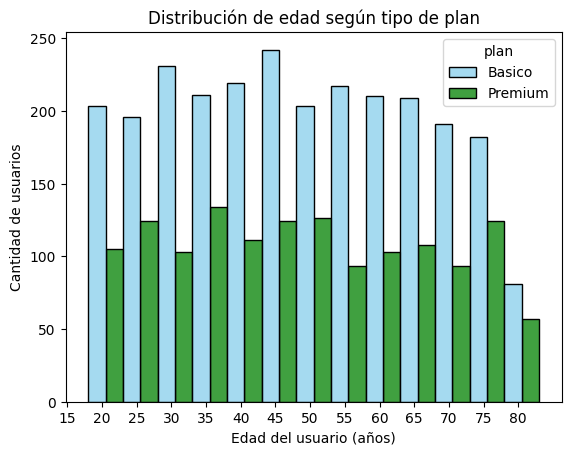

In [30]:
# Histograma para visualizar la edad (age)

sns.histplot(
    data=user_profile, 
    x='age', 
    hue='plan',
    binwidth=5,
    multiple='dodge',
    palette=['skyblue', 'green'], 
    edgecolor = 'black'
)
plt.title('Distribución de edad según tipo de plan')
plt.ylabel('Cantidad de usuarios')
plt.xlabel('Edad del usuario (años)')
plt.xticks(range(15, 85, 5))
plt.show()


💡Insights: 
- La distribución de edades no muestra un grupo de edad dominante que prefiera cierto tipo de plan. Hay un caída de usuarios a la derecha, que puede deberse a menos usuarios de edad avanzada (75 años en adelante). A lo largo del gráfico se confirma que el plan más utilizado es el Basico.

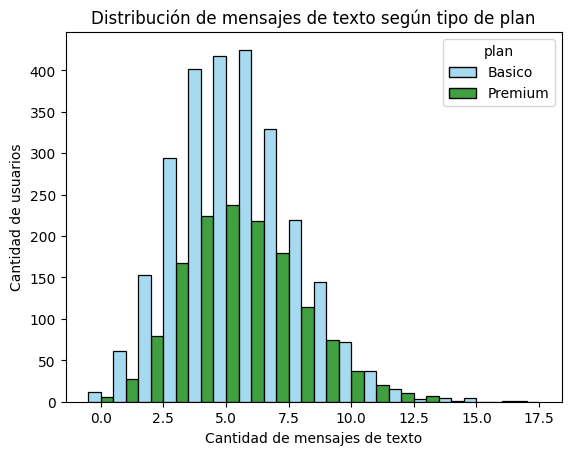

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile, 
    discrete=True,
    x='cant_mensajes', 
    hue='plan', 
    multiple='dodge',
    palette=['skyblue', 'green'], 
    edgecolor = 'black'
)
plt.title('Distribución de mensajes de texto según tipo de plan')
plt.ylabel('Cantidad de usuarios')
plt.xlabel('Cantidad de mensajes de texto')
plt.show()


💡Insights: 
- La distribución tiene forma de campana, con un ligero sesgo a la derecha. Los valores más altos se concentran entre 3-7 mensajes de texto. A partir de 8 baja y tiene una cola hasta 17 mensajes. Ambos planes tienen comportamientos similares, no parece haber diferencias que indiquen que la cantidad de mensajes de texto distingan a un plan del otro.

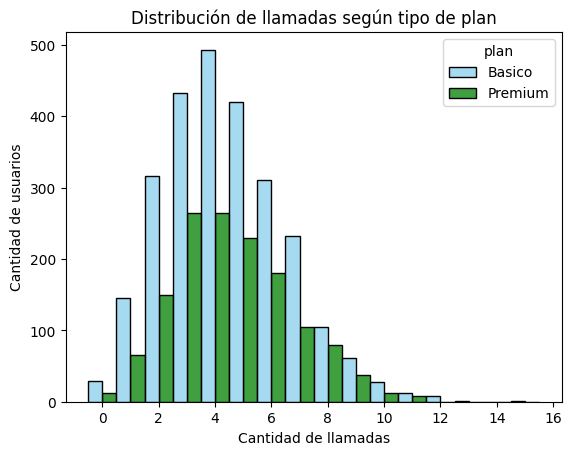

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile, 
    discrete=True, 
    x='cant_llamadas', 
    hue='plan', 
    multiple='dodge',
    palette=['skyblue', 'green'], 
edgecolor = 'black'
)
plt.title('Distribución de llamadas según tipo de plan')
plt.ylabel('Cantidad de usuarios')
plt.xlabel('Cantidad de llamadas')
plt.show()


💡Insights: 
- La distribución tiene forma de campana, con un ligero sesgo a la derecha. Los valores más altos se concentran entre 2-7 llamadas, con el máximo en 4 llamadas. Al igual que en los mensajes de texto, ambos planes tienen comportamientos similares, no parece haber diferencias que indiquen que la cantidad de llamadas distingan a un plan del otro.

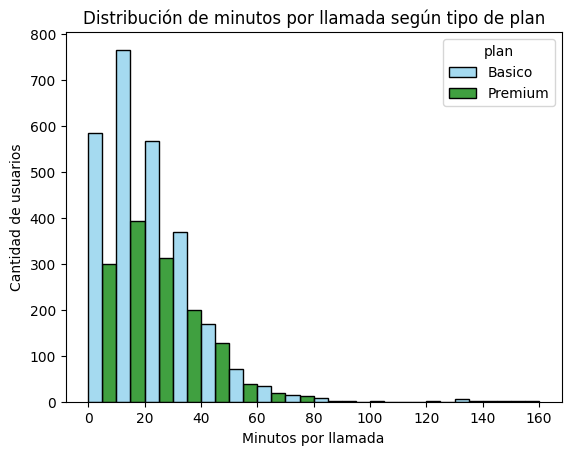

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile, 
    binwidth=10, 
    x='cant_minutos_llamada', 
    hue='plan', 
    multiple='dodge',
    palette=['skyblue', 'green'], 
    edgecolor = 'black')
plt.title('Distribución de minutos por llamada según tipo de plan')
plt.ylabel('Cantidad de usuarios')
plt.xlabel('Minutos por llamada')
plt.show()


💡Insights: 
- La distribución tiene un notable sesgo a la derecha, hay valores atípicos después de los 60 minutos hasta llegar a los 160 minutos. La mayor cantidad de minutos se registra entre 15-25 minutos por llamada. Ambos planes tienen comportamientos similares.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

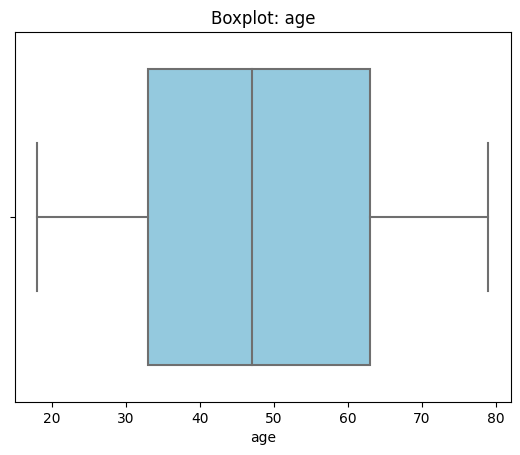

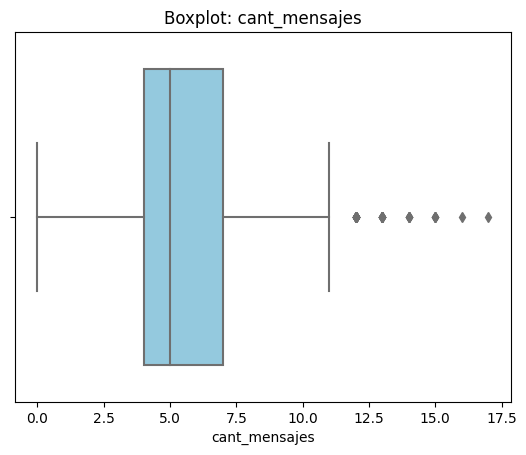

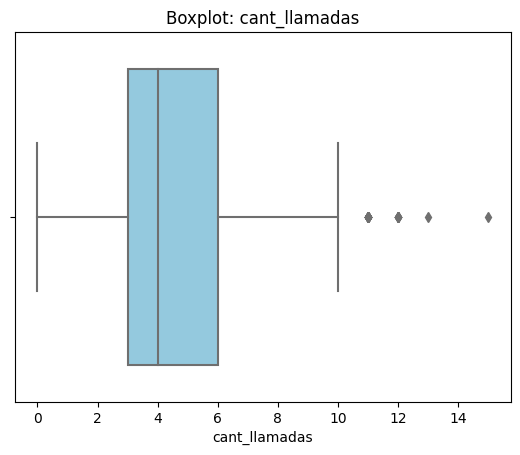

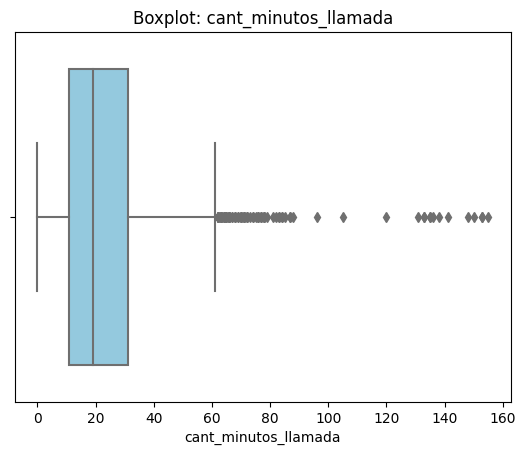

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(
        data=user_profile,
        x=col,
        color='skyblue'
    )
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: no presenta outliers.
- cant_mensajes: sí presenta outliers.
- cant_llamadas: sí presenta outliers.
- cant_minutos_llamada: es la columna con outliers más lejos del rango.

In [35]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    print(col)
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f'IQR: ', IQR)
    print(f'Límite superior: ', limite_superior)




cant_mensajes
IQR:  3.0
Límite superior:  11.5
cant_llamadas
IQR:  3.0
Límite superior:  10.5
cant_minutos_llamada
IQR:  20.0
Límite superior:  61.0


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.337834
std,2.358416,2.144238,16.589929
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.000000
50%,5.000000,4.000000,19.000000
75%,7.000000,6.000000,31.000000
max,17.000000,15.000000,155.000000


💡Insights: 
- cant_mensajes: se pueden mantener los outliers, son valores que están ligeramente por encima del límite (11.5), pero los valores máximos (17) son reales. Corresponden a usuarios que pueden enviar más mensajes que la media.
- cant_llamadas: se pueden mantener los outliers, son valores que están ligeramente por encima del límite (10.5), pero los valores máximos (15) son reales. Corresponden a usuarios que pueden hacer más llamadas que la media.
- cant_minutos_llamada: Se mantienen los outliers bajo criterio, pero se marcan para seguimiento. La cola es larga (máx. 155, media de 22 y límite de 61), lo cual es compatible con usuarios que hacen llamadas largas. No hay valores imposibles, aunque se recomienda validar los casos más extremos por si indican fraude o errores de registro.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
categorias = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
ondiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.0,Alto uso,Adulto Mayor
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.0,Bajo uso,Joven


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

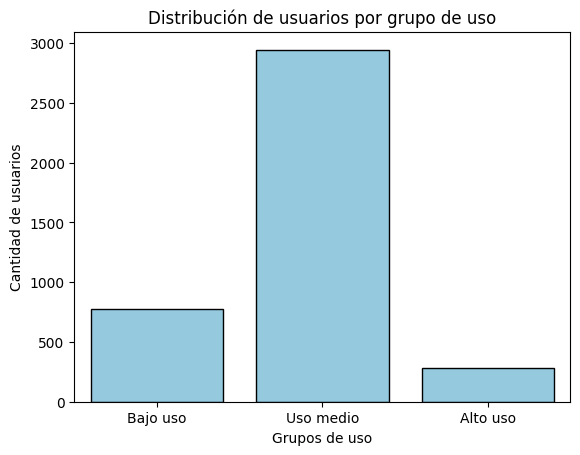

In [41]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    color='skyblue',
    edgecolor='black'
)
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupos de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

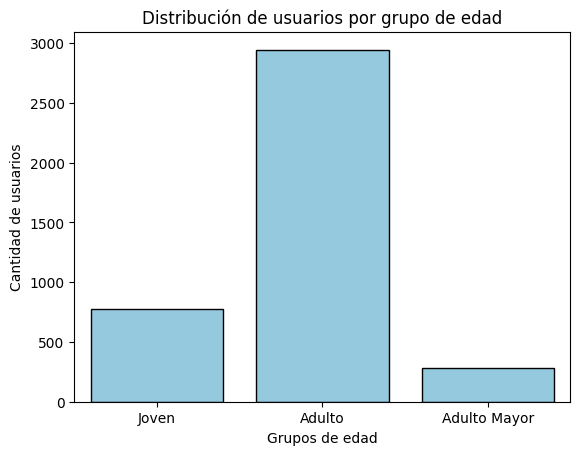

In [42]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    color='skyblue',
    edgecolor='black'
)
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupos de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **`age` (users):** tenía un valor centinel `-999`. Distorsionaba la media (33.7 frente a una mediana de 47). Se reemplazó por la mediana.
- **`city` (users):** 469 nulos (11.7%) y 96 registros con "?". Al imputarse quedaron 565 registros con valores nulos.
- **`date` (usage):** 50 nulos (0.125% de 40,000 registros) y fechas fuera de rango, convertidas a nulo.
- **`duration` y `length` (usage):** 55.2% y 44.7% de nulos, pero no son un error: `duration` solo aplica a llamadas y `length` solo a mensajes. No se imputaron; se analizan por separado según `type`.
- **`churn_date` (users):** 88.3% de nulos (3,534 usuarios). Es información, no un problema: indica clientes activos.


🔍 **Segmentos por Edad**
- La base es muy homogénea: edades de 18 a 79 años distribuidas casi de forma uniforme. Se segmentaron grupos de edad: Joven <30 años, Adulto >30 <60 años, Adulto Mayor >60 años.
- El plan Básico concentra 64.9% de los clientes (2,595) y Premium 35.1% (1,405). Esta proporción se mantiene en todos los rangos de edad, por lo que la edad no explica qué plan se contrata.
- Uso por grupo de edad: los adultos son el grupo de edad más activo con cerca de 3000 usuarios.


📊 **Segmentos por Nivel de Uso**
- El cliente típico (mediana) envía 5 mensajes, hace 4 llamadas y acumula 19 minutos de llamada. Las distribuciones tienen sesgo a la derecha.
- Se crearon segmentos por nivel de uso: Bajo uso < 5 mensajes o llamadas, Uso medio > 5 y < 10 llamadas o mensajes, Alto uso > 10.
- El nivel de uso más común es Uso medio, con cerca de 3000 usuarios.
- Outliers (método IQR): mensajes > 11.5 (máx. 17), llamadas > 10.5 (máx. 15) y minutos > 61 (máx. 155). Se mantuvieron porque son valores plausibles y corresponden a clientes de uso intensivo, que son relevantes para el negocio. Los minutos extremos se recomienda validarlos por si indican fraude o errores de registro.

➡️ Esto sugiere que el uso de llamadas y mensajes no diferencia a los clientes Premium de los Básicos. El comportamiento está más ligado al nivel de uso que al plan contratado o a la edad.

💡 **Recomendaciones**
1. **Revisar la propuesta de valor de Premium:** si su uso es igual al de Básico, el cliente puede no percibir qué obtiene por el precio extra. Comparar el uso real con los minutos y GB incluidos en `plans.csv`.
2. **Plan ligero para bajo uso:** se observó un grupo reducido de clientes con poco uso, así que un plan más económico podría retener a quienes hoy pagan por capacidad que no usan.
3. **Oferta para alto uso:** paquetes o complementos para el segmento de uso intensivo, que hoy puede estar pagando costos por extra.
4. **Monitoreo de atípicos:** alertas para usuarios con minutos o mensajes extremos (posible fraude o error de registro).
5. **Calidad de datos en origen:** validaciones en el registro (edad, ciudad con catálogo cerrado) y fechas en rango, para evitar `-999`, "?" y nombres inconsistentes.
6. **Siguiente paso analítico:** comparar el uso de los clientes que cancelaron (`churn_date`) con el de los activos, para identificar señales de abandono.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`